# Smoke from the Ground and from a Model: ASOS + HRRR-Smoke + HRRR Weather Maps
### Case study: Canadian wildfire smoke over the Mid-Atlantic, June 2023
**What you will do**
1. Download ASOS observations (quick review of the first notebook)
2. Download **HRRR-Smoke** model data: smoke near the ground and smoke in the whole air column
3. Compare the model smoke with what the airports saw
4. Make **synoptic weather maps** at the surface and at 850, 700 and 500 hPa
5. Put smoke and wind on one map to see how the smoke travelled

## 1. Background
### What is ASOS?
**ASOS** = **A**utomated **S**urface **O**bserving **S**ystem.

- About 900 automatic weather stations across the U.S., mostly at **airports**.
- Run by the National Weather Service, the FAA and the Department of Defense.
- They report the weather **at least once every hour**, all day, every day.
- Each report is a short coded message called a **METAR**,
### What is HRRR?
**HRRR** (High-Resolution Rapid Refresh) is a NOAA weather forecast model.
- It covers the whole continental U.S. with grid boxes **3 km** wide.
- A new run starts **every hour**.
- Forecast hour 0 (written `F00`) is the model's best guess of the weather *right now*.
  We call this the **analysis**. We will use F00 in this notebook.

### What is HRRR-Smoke?
Since late 2020 the operational HRRR also carries **wildfire smoke**.
- Satellites detect fires and measure how much heat they give off (fire radiative power).
- The model turns that heat into an estimate of how much smoke the fire releases.
- The model winds then carry the smoke around, up and down.
### What is a synoptic map?
"Synoptic" means "seen together". A synoptic map shows the weather over a large area at
**one moment**, so we can see the big pressure systems that steer the air (and the smoke).

------

## 2. Set up: Import Library and tools we need 
----
*On Google Colab, remove the # in the next cell and run it once.
On your own computer use: `conda install -c conda-forge herbie-data cartopy`*

In [1]:
# !pip install herbie-data cartopy cfgrib eccodes

In [2]:
import requests                  # downloads data from websites
import numpy as np               # math with arrays
import pandas as pd              # tables of data
import matplotlib.pyplot as plt  # plots
import matplotlib.dates as mdates
from io import StringIO

import cartopy.crs as ccrs       # maps
import cartopy.feature as cfeature
from scipy.ndimage import gaussian_filter
from herbie import Herbie        # downloads HRRR model data

plt.rcParams["figure.dpi"] = 110
print("All set")

All set


## 3. Choose our station, Dates and Map time
We pick five big airports along the **I-95 corridor** in the Mid-Atlantic.
Station IDs are the airport codes without the leading "K".

| Code | Airport | City |
|---|---|---|
| PHL | Philadelphia International | Philadelphia, PA |
| BWI | Baltimore/Washington International | Baltimore, MD |
| DCA | Reagan National | Washington, DC |
| IAD | Dulles International | Northern Virginia |
| RIC | Richmond International | Richmond, VA |



In [3]:
stations = ["PHL", "BWI", "DCA", "IAD", "RIC"]
# duration of the date we are observing in the data
start_date = "2023-06-05"  
end_date   = "2023-06-11" 
# hour used for all maps (UTC)
map_time = "2023-06-07 18:00"  
# One colour per station so every plot matches
colors = {"PHL": "tab:purple", "BWI": "tab:blue", "DCA": "tab:red",
          "IAD": "tab:green",  "RIC": "tab:orange"}

# PART 1: ASOS weather stations

ASOS stations report the weather every hour. They do not measure pollution,
but some variables are good clues:

| Variable | Name | Clue |
|---|---|---|
| Visibility | vsby | Smoke and haze reduce visibility |
| Weather code | wxcodes | FU = smoke, HZ = haze, BR = mist |
| Wind direction | drct | Where the air came from |
| Wind speed | sknt | Light wind lets pollution build up |
| Humidity | relh | Helps tell fog from smoke |
| Temperature, dew point | tmpf, dwpf | Sunny hot days make ozone |

## 3. Download ASOS data
The Iowa Environmental Mesonet (IEM) gives ASOS data for free.
We ask for data with a web address. The part after `?` lists our settings.
Try this address in your browser: it gives BWI temperature on 7 June 2023.

`https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py?station=BWI&data=tmpf&year1=2023&month1=6&day1=7&year2=2023&month2=6&day2=8&tz=Etc/UTC&format=onlycomma`

Python can do the same with `requests.get`.

In [4]:
base_address = "https://mesonet.agron.iastate.edu/cgi-bin/request/asos.py"

settings = {"station": "BWI", "data": "tmpf",
            "year1": 2023, "month1": 6, "day1": 7,
            "year2": 2023, "month2": 6, "day2": 8,
            "tz": "Etc/UTC", "format": "onlycomma"}

response = requests.get(base_address, params=settings, timeout=60)
print("Status code:", response.status_code)   # 200 means OK
print(response.text[:200])

Status code: 200
station,valid,tmpf
BWI,2023-06-07 00:00,M
BWI,2023-06-07 00:05,M
BWI,2023-06-07 00:10,M
BWI,2023-06-07 00:15,M
BWI,2023-06-07 00:20,M
BWI,2023-06-07 00:25,M
BWI,2023-06-07 00:30,M
BWI,2023-06-07 00:35


Now we put this in a function so we can ask for many stations and variables at once.
`latlon` adds the station location. We save the table to a CSV file so we do not need to download it again.

In [5]:
def fetch_asos_many(stations, variables, start_date, end_date):
    start = pd.Timestamp(start_date)
    end = pd.Timestamp(end_date)
    settings = {
        "station": stations,
        "data": variables,
        "year1": start.year, "month1": start.month, "day1": start.day,
        "year2": end.year,   "month2": end.month,   "day2": end.day,
        "tz": "Etc/UTC",
        "format": "onlycomma",
        "latlon": "yes",
        "missing": "empty",
        "report_type": 3,      # regular hourly reports
    }
    response = requests.get(base_address, params=settings, timeout=120)
    return pd.read_csv(StringIO(response.text))

variables = ["tmpf", "dwpf", "relh", "drct", "sknt", "vsby", "wxcodes"]
df = fetch_asos_many(stations, variables, start_date, end_date)
df.to_csv("asos_midatlantic_june2023.csv", index=False)
print("Downloaded", len(df), "rows")
df.head()

Downloaded 720 rows


,station,valid,lon,lat,tmpf,dwpf,relh,drct,sknt,vsby,wxcodes
0,IAD,2023-06-05 00:52,-77.4473,38.9348,69.0,54.0,58.60,260.0,3.0,10.0,NaN
1,DCA,2023-06-05 00:52,-77.0345,38.8472,71.0,54.0,54.73,200.0,9.0,10.0,NaN
2,PHL,2023-06-05 00:54,-75.2266,39.8734,61.0,48.0,62.23,160.0,4.0,10.0,NaN
3,BWI,2023-06-05 00:54,-76.6841,39.1733,68.0,55.0,63.12,200.0,3.0,9.0,NaN
4,RIC,2023-06-05 00:54,-77.3234,37.5115,62.0,54.0,74.75,210.0,3.0,10.0,NaN


## 4. Clean the data
- Text to time and numbers (blanks become NaN, meaning missing)
- Convert to metric units
- Mark hours with smoke (FU) or haze (HZ)

In [6]:
df["time"] = pd.to_datetime(df["valid"], utc=True)
for col in ["tmpf", "dwpf", "relh", "drct", "sknt", "vsby", "lat", "lon"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["temp_C"]  = (df["tmpf"] - 32) * 5 / 9   # F to C
df["dewpt_C"] = (df["dwpf"] - 32) * 5 / 9
df["wind_ms"] = df["sknt"] * 0.514444       # knots to m/s
df["vis_km"]  = df["vsby"] * 1.609344       # miles to km

df["wxcodes"] = df["wxcodes"].fillna("")
df["smoke_or_haze"] = df["wxcodes"].str.contains(r"\bFU\b|\bHZ\b")

sites = df.groupby("station")[["lat", "lon"]].first()   # station locations
sites

,lat,lon
station,,
BWI,39.1733,-76.6841
DCA,38.8472,-77.0345
IAD,38.9348,-77.4473
PHL,39.8734,-75.2266
RIC,37.5115,-77.3234


## 5. Visibility
ASOS visibility stops at 10 miles (16 km), so a flat line at the top means clear air.
x marks show hours with smoke or haze reported.

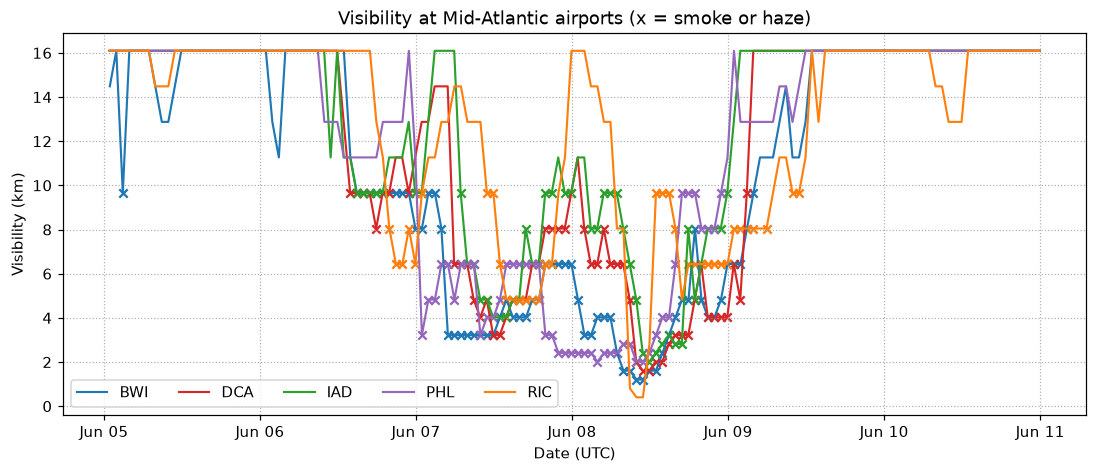

,station,time,vis_km,wxcodes
378,PHL,2023-06-08 03:54:00+00:00,2.011680,HZ FU
408,BWI,2023-06-08 09:54:00+00:00,1.207008,HZ
409,RIC,2023-06-08 09:54:00+00:00,0.402336,FG
410,DCA,2023-06-08 10:52:00+00:00,1.609344,HZ
416,IAD,2023-06-08 11:52:00+00:00,2.011680,HZ


In [7]:
def nice_time_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.set_xlabel("Date (UTC)")

fig, ax = plt.subplots(figsize=(12, 4.5))
for st, g in df.groupby("station"):
    ax.plot(g["time"], g["vis_km"], color=colors[st], lw=1.4, label=st)
    smoky = g[g["smoke_or_haze"]]
    ax.scatter(smoky["time"], smoky["vis_km"], marker="x", s=30, color=colors[st])
ax.set_ylabel("Visibility (km)")
ax.set_title("Visibility at Mid-Atlantic airports (x = smoke or haze)")
ax.legend(ncol=5, loc="lower left")
ax.grid(ls=":")
nice_time_axis(ax)
plt.show()

# Worst hour at each station
worst = df.loc[df.groupby("station")["vis_km"].idxmin(), ["station", "time", "vis_km", "wxcodes"]]
worst.sort_values("time")

Question: Did the smoke reach all airports at the same time?

## 6. Smoke hours per day

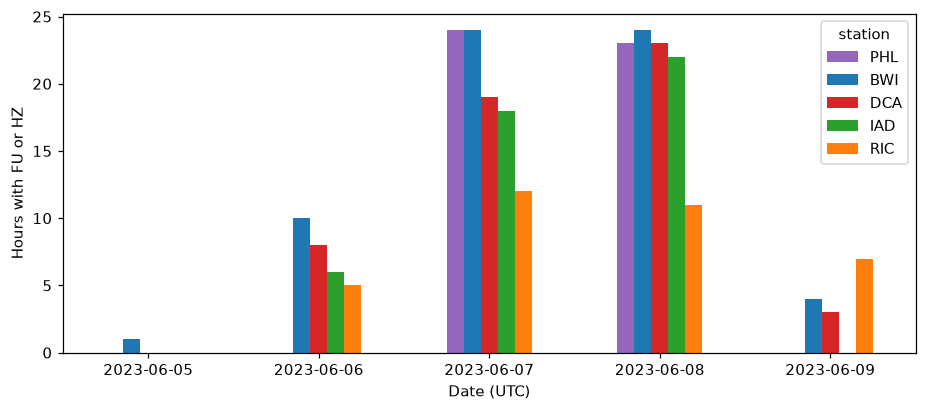

station,PHL,BWI,DCA,IAD,RIC
date,,,,,
2023-06-05,0,1,0,0,0
2023-06-06,0,10,8,6,5
2023-06-07,24,24,19,18,12
2023-06-08,23,24,23,22,11
2023-06-09,0,4,3,0,7


In [8]:
df["date"] = df["time"].dt.date
smoke_hours = df[df["smoke_or_haze"]].groupby(["date", "station"]).size().unstack(fill_value=0)
smoke_hours = smoke_hours.reindex(columns=stations, fill_value=0)

smoke_hours.plot(kind="bar", figsize=(10, 4), color=[colors[s] for s in smoke_hours.columns])
plt.ylabel("Hours with FU or HZ")
plt.xlabel("Date (UTC)")
plt.xticks(rotation=0)
plt.show()
smoke_hours

## 7. Where did the air come from?
Wind direction is where the wind comes from: 0 = North, 90 = East, 180 = South, 270 = West.
We compare hours with and without smoke.

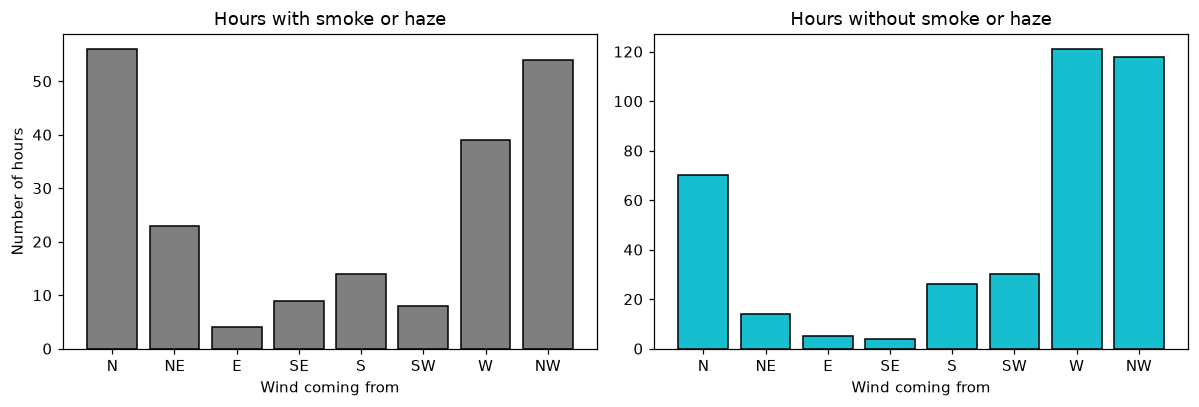

In [9]:
def to_compass(deg):
    if pd.isna(deg) or deg == 0:      # 0 means calm
        return None
    names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
    return names[int(((deg + 22.5) % 360) // 45)]

df["wind_from"] = df["drct"].apply(to_compass)
order = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
smoky_counts = df[df["smoke_or_haze"]]["wind_from"].value_counts().reindex(order, fill_value=0)
clear_counts = df[~df["smoke_or_haze"]]["wind_from"].value_counts().reindex(order, fill_value=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(order, smoky_counts, color="tab:gray", edgecolor="k")
ax1.set_title("Hours with smoke or haze")
ax1.set_ylabel("Number of hours")
ax2.bar(order, clear_counts, color="tab:cyan", edgecolor="k")
ax2.set_title("Hours without smoke or haze")
for ax in (ax1, ax2):
    ax.set_xlabel("Wind coming from")
plt.tight_layout()
plt.show()

Question: The fires were in Quebec, Canada. Which direction is Quebec from Baltimore? Does the wind agree?

## 8. Smoke or fog?
Fog happens when humidity is near 100 percent. Smoke can lower visibility in dry air.
Low visibility with low humidity points to particles in the air.

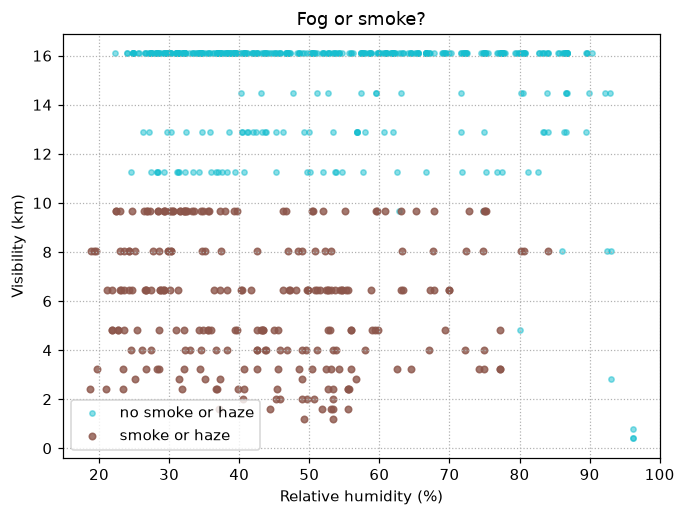

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
clear = df[~df["smoke_or_haze"]]
smoky = df[df["smoke_or_haze"]]
ax.scatter(clear["relh"], clear["vis_km"], s=12, alpha=0.5, color="tab:cyan", label="no smoke or haze")
ax.scatter(smoky["relh"], smoky["vis_km"], s=18, alpha=0.8, color="tab:brown", label="smoke or haze")
ax.set_xlabel("Relative humidity (%)")
ax.set_ylabel("Visibility (km)")
ax.set_title("Fog or smoke?")
ax.legend()
ax.grid(ls=":")
plt.show()

## 9. One station, several variables
Change `my_station` to look at other airports.

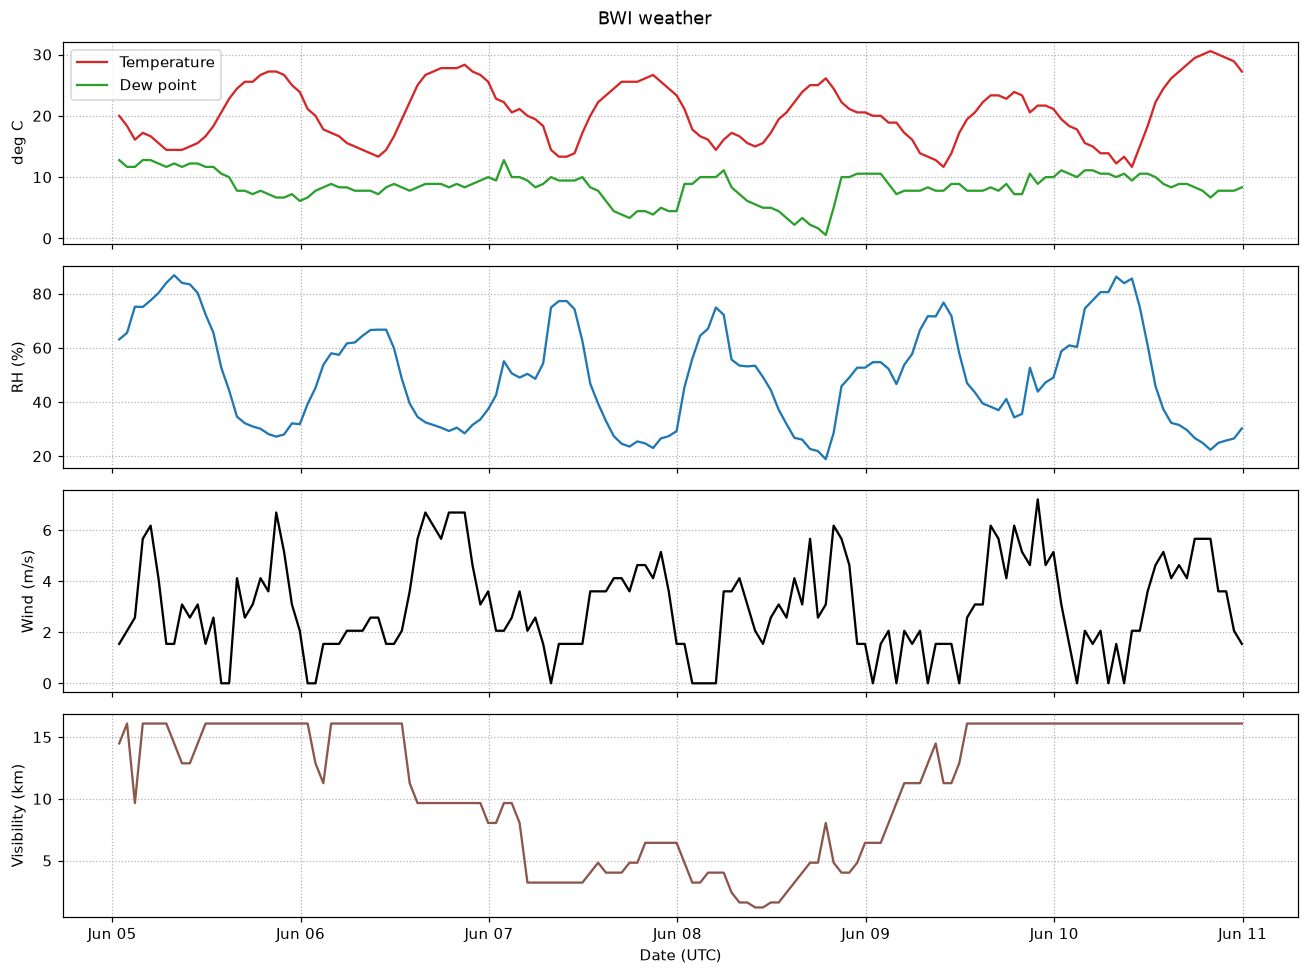

In [11]:
my_station = "BWI"
g = df[df["station"] == my_station]

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g["time"], g["temp_C"], color="tab:red", label="Temperature")
axes[0].plot(g["time"], g["dewpt_C"], color="tab:green", label="Dew point")
axes[0].set_ylabel("deg C")
axes[0].legend(loc="upper left")
axes[1].plot(g["time"], g["relh"], color="tab:blue")
axes[1].set_ylabel("RH (%)")
axes[2].plot(g["time"], g["wind_ms"], color="k")
axes[2].set_ylabel("Wind (m/s)")
axes[3].plot(g["time"], g["vis_km"], color="tab:brown")
axes[3].set_ylabel("Visibility (km)")
for ax in axes:
    ax.grid(ls=":")
nice_time_axis(axes[-1])
fig.suptitle(f"{my_station} weather")
plt.tight_layout()
plt.show()

-------------------

Question: On the smokiest day, was the afternoon cooler than other days? Why? (Hint: sunlight.)

# PART 2: HRRR smoke model

**HRRR** is a NOAA weather model with 3 km grid boxes over the whole U.S. It runs every hour.
Forecast hour 0 (F00) is the model's best estimate of the current weather.

**HRRR-Smoke** uses satellite fire detections to estimate smoke from fires,
then the model winds move the smoke. We use two fields:

| Field | Meaning | File units | Our units |
|---|---|---|---|
| MASSDEN (8 m) | Smoke near the ground | kg/m3 | ug/m3 |
| COLMD | All smoke in the air column | kg/m2 | mg/m2 |

For comparison, the EPA 24-hour limit for PM2.5 is 35 ug/m3.

## 10. Get HRRR data with Herbie
Herbie downloads only the fields we ask for, not the whole large file.
- `product="sfc"`: surface file (includes smoke)
- `product="prs"`: pressure level file
- `fxx=0`: forecast hour 0

In [12]:
H = Herbie(map_time, model="hrrr", product="sfc", fxx=0)
H.inventory(":MASSDEN:|:COLMD:")    # list the smoke fields in the file

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2023-Jun-07 18:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
75,76,43553730,44296297.0,43553730-44296297,2023-06-07 18:00:00,2023-06-07 18:00:00,MASSDEN,8 m above ground,anl,:MASSDEN:8 m above ground:anl:
108,109,67596140,68534752.0,67596140-68534752,2023-06-07 18:00:00,2023-06-07 18:00:00,COLMD,entire atmosphere (considered as a single layer),anl,:COLMD:entire atmosphere (considered as a sing...


The `search_this` column is the text we use to ask for a field.
This helper gets one field and changes longitude from 0 to 360 into -180 to 180.

In [13]:
def get_hrrr(time, search, product="sfc", fxx=0):
    H = Herbie(time, model="hrrr", product=product, fxx=fxx, verbose=False)
    ds = H.xarray(search)
    field = ds[list(ds.data_vars)[0]]
    lon = ((field.longitude + 180) % 360) - 180
    return field.assign_coords(longitude=lon)

## 11. Map helpers
`extent` is the map box: [west, east, south, north].

In [14]:
wide_extent = [-90, -64, 34, 52]        # Mid-Atlantic to Quebec
zoom_extent = [-80, -73, 36.5, 41.5]    # I-95 corridor

def make_map(extent, title=""):
    proj = ccrs.LambertConformal(central_longitude=-80, standard_parallels=(38.5, 38.5))
    fig = plt.figure(figsize=(9, 7))
    ax = plt.axes(projection=proj)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
    ax.add_feature(cfeature.STATES, linewidth=0.4, edgecolor="0.4")
    ax.add_feature(cfeature.BORDERS, linewidth=0.7)
    ax.set_title(title)
    return fig, ax

def add_stations(ax, labels=None):
    for st, row in sites.iterrows():
        ax.plot(row["lon"], row["lat"], "*", ms=13, color=colors[st], mec="k",
                transform=ccrs.PlateCarree())
        text = st if labels is None else f"{st} {labels.get(st, '')}"
        ax.text(row["lon"] + 0.1, row["lat"] + 0.05, text, fontsize=9, fontweight="bold",
                transform=ccrs.PlateCarree())

## 12. Smoke near the ground
1 kg = 1e9 ug, so we multiply by 1e9.

Max smoke: 5097.1 ug/m3


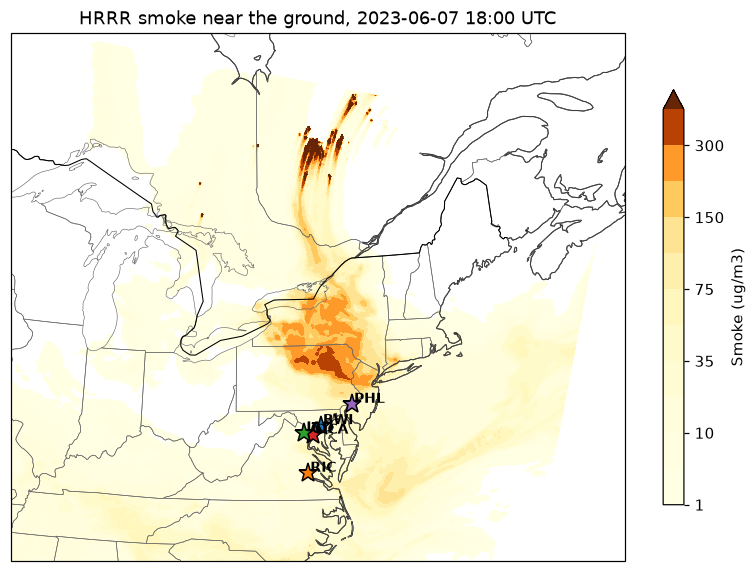

In [16]:
smoke_sfc = get_hrrr(map_time, ":MASSDEN:8 m above ground") * 1e9   # kg/m3 to ug/m3
print("Max smoke:", round(float(smoke_sfc.max()), 1), "ug/m3")

smoke_levels = [1, 5, 10, 25, 35, 50, 75, 100, 150, 200, 300, 500]

fig, ax = make_map(wide_extent, f"HRRR smoke near the ground, {map_time} UTC")
cf = ax.contourf(smoke_sfc.longitude, smoke_sfc.latitude, smoke_sfc, levels=smoke_levels,
                 cmap="YlOrBr", extend="max", transform=ccrs.PlateCarree())
plt.colorbar(cf, ax=ax, shrink=0.7, label="Smoke (ug/m3)")
add_stations(ax)
plt.show()

## 13. Does the model agree with the airports?
We zoom in and write the observed visibility next to each airport.
Airports in thick model smoke should have low visibility.

C:\Users\Sharad\anaconda3\envs\herbie_env\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


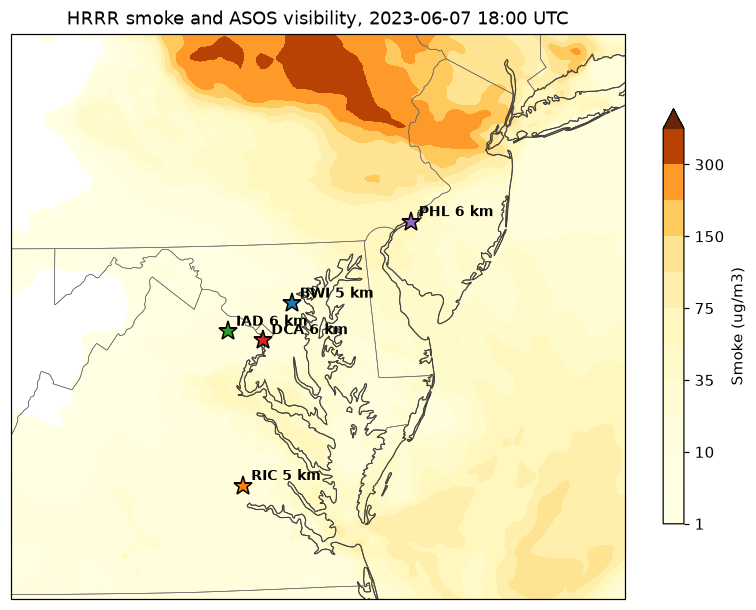

In [17]:
t = pd.Timestamp(map_time, tz="UTC")
near_time = df[(df["time"] - t).abs() <= pd.Timedelta("30min")]
vis_now = near_time.groupby("station")["vis_km"].first()
labels = {st: f"{v:.0f} km" for st, v in vis_now.items()}

fig, ax = make_map(zoom_extent, f"HRRR smoke and ASOS visibility, {map_time} UTC")
cf = ax.contourf(smoke_sfc.longitude, smoke_sfc.latitude, smoke_sfc, levels=smoke_levels,
                 cmap="YlOrBr", extend="max", transform=ccrs.PlateCarree())
plt.colorbar(cf, ax=ax, shrink=0.7, label="Smoke (ug/m3)")
add_stations(ax, labels)
plt.show()

## 14. Smoke in the whole air column
Smoke often travels high above the ground. COLMD adds up all smoke from the ground to the top.
High column smoke but low ground smoke means the smoke is mostly aloft.

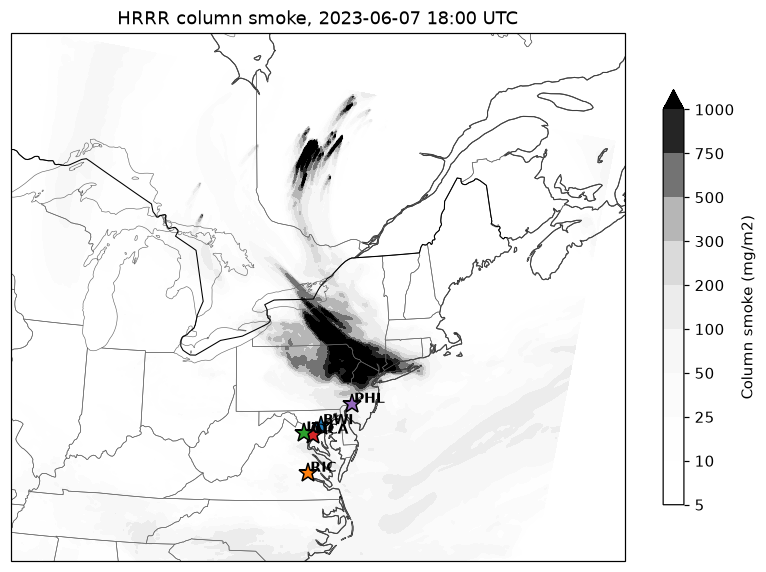

In [18]:
smoke_col = get_hrrr(map_time, ":COLMD:entire atmosphere") * 1e6   # kg/m2 to mg/m2
col_levels = [5, 10, 25, 50, 100, 200, 300, 500, 750, 1000]

fig, ax = make_map(wide_extent, f"HRRR column smoke, {map_time} UTC")
cf = ax.contourf(smoke_col.longitude, smoke_col.latitude, smoke_col, levels=col_levels,
                 cmap="Greys", extend="max", transform=ccrs.PlateCarree())
plt.colorbar(cf, ax=ax, shrink=0.7, label="Column smoke (mg/m2)")
add_stations(ax)
plt.show()

## 15. Model smoke vs observed visibility
We take the HRRR smoke at the grid point nearest each airport, every 3 hours.
This downloads 25 small files and takes a few minutes.

In [19]:
def nearest_value(field, lat, lon):
    dist = (field.latitude - lat) ** 2 + (field.longitude - lon) ** 2
    iy, ix = np.unravel_index(np.argmin(dist.values), dist.shape)
    return float(field.values[iy, ix])

times = pd.date_range("2023-06-06 00:00", "2023-06-09 00:00", freq="3h")
rows = []
for time in times:
    field = get_hrrr(time, ":MASSDEN:8 m above ground") * 1e9
    for st, row in sites.iterrows():
        rows.append({"time": time.tz_localize("UTC"), "station": st,
                     "smoke_ugm3": nearest_value(field, row["lat"], row["lon"])})
    print("done", time)
hrrr_pts = pd.DataFrame(rows)

done 2023-06-06 00:00:00
done 2023-06-06 03:00:00
done 2023-06-06 06:00:00
done 2023-06-06 09:00:00
done 2023-06-06 12:00:00
done 2023-06-06 15:00:00
done 2023-06-06 18:00:00
done 2023-06-06 21:00:00
done 2023-06-07 00:00:00
done 2023-06-07 03:00:00
done 2023-06-07 06:00:00
done 2023-06-07 09:00:00
done 2023-06-07 12:00:00
done 2023-06-07 15:00:00
done 2023-06-07 18:00:00
done 2023-06-07 21:00:00
done 2023-06-08 00:00:00
done 2023-06-08 03:00:00
done 2023-06-08 06:00:00
done 2023-06-08 09:00:00
done 2023-06-08 12:00:00
done 2023-06-08 15:00:00
done 2023-06-08 18:00:00
done 2023-06-08 21:00:00
done 2023-06-09 00:00:00


Question: When model smoke goes up, does visibility go down? Is the timing right?

# PART 3: Weather maps

A synoptic map shows the weather over a large area at one time.
We look at several pressure levels. Pressure drops with height:

| Level | Height | Use |
|---|---|---|
| Surface | ground | Highs, lows, surface wind |
| 850 hPa | about 1.5 km | Air just above us |
| 700 hPa | about 3 km | Common height for smoke plumes |
| 500 hPa | about 5.5 km | Steers big weather systems |

1 hPa = 1 mb. Height lines show where the pressure level sits. Low heights mean a low.
Wind blows along the lines, counter-clockwise around a low.

## 16. Wind helper
HRRR winds point along the model grid, not true north. This function fixes that.
Wind barbs point to where the wind comes from. Short line = 5 knots, long line = 10 knots.

In [20]:
def grid_to_earth(u, v):
    # HRRR grid: central longitude -97.5, true latitude 38.5
    angle = np.sin(np.radians(38.5)) * np.radians(u.longitude + 97.5)
    u_earth = np.cos(angle) * u + np.sin(angle) * v
    v_earth = -np.sin(angle) * u + np.cos(angle) * v
    return u_earth, v_earth

def add_barbs(ax, u, v, skip=40):
    u_e, v_e = grid_to_earth(u, v)
    s = slice(None, None, skip)     # every 40th point so the map is not crowded
    ax.barbs(u.longitude.values[s, s], u.latitude.values[s, s],
             u_e.values[s, s] * 1.944, v_e.values[s, s] * 1.944,   # m/s to knots
             length=5.5, linewidth=0.6, transform=ccrs.PlateCarree())

## 17. Surface map
Black lines: sea level pressure every 4 hPa. Colors: temperature at 2 m. Barbs: wind at 10 m.

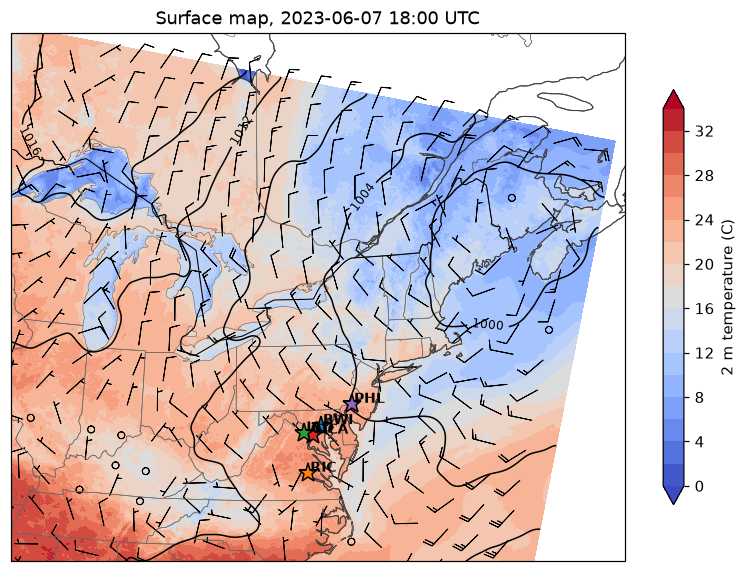

In [22]:
mslp = get_hrrr(map_time, ":MSLMA:mean sea level") / 100      # Pa to hPa
t2m  = get_hrrr(map_time, ":TMP:2 m above ground") - 273.15   # K to C
u10  = get_hrrr(map_time, ":UGRD:10 m above ground")
v10  = get_hrrr(map_time, ":VGRD:10 m above ground")

fig, ax = make_map(wide_extent, f"Surface map, {map_time} UTC")
cf = ax.contourf(t2m.longitude, t2m.latitude, t2m, levels=np.arange(0, 36, 2),
                 cmap="coolwarm", extend="both", transform=ccrs.PlateCarree())
plt.colorbar(cf, ax=ax, shrink=0.7, label="2 m temperature (C)")

mslp_smooth = gaussian_filter(mslp.values, sigma=4)    # smooth small wiggles
cs = ax.contour(mslp.longitude, mslp.latitude, mslp_smooth, levels=np.arange(980, 1040, 4),
                colors="k", linewidths=1, transform=ccrs.PlateCarree())
ax.clabel(cs, fmt="%d", fontsize=8)
add_barbs(ax, u10, v10)
add_stations(ax)
plt.show()

## 18. Pressure level maps
Black lines: height in decameters (1 dam = 10 m). Colors: wind speed. Barbs: wind.

In [23]:
def pressure_level_map(time, level, interval):
    hgt = get_hrrr(time, f":HGT:{level} mb", product="prs") / 10    # m to dam
    u   = get_hrrr(time, f":UGRD:{level} mb", product="prs")
    v   = get_hrrr(time, f":VGRD:{level} mb", product="prs")
    speed_kt = np.sqrt(u**2 + v**2) * 1.944

    fig, ax = make_map(wide_extent, f"{level} hPa, {time} UTC")
    cf = ax.contourf(u.longitude, u.latitude, speed_kt, levels=np.arange(10, 80, 5),
                     cmap="BuPu", extend="max", transform=ccrs.PlateCarree())
    plt.colorbar(cf, ax=ax, shrink=0.7, label=f"{level} hPa wind speed (knots)")

    hgt_smooth = gaussian_filter(hgt.values, sigma=4)
    start = np.floor(np.nanmin(hgt_smooth) / interval) * interval
    cs = ax.contour(hgt.longitude, hgt.latitude, hgt_smooth,
                    levels=np.arange(start, np.nanmax(hgt_smooth) + interval, interval),
                    colors="k", linewidths=1, transform=ccrs.PlateCarree())
    ax.clabel(cs, fmt="%d", fontsize=8)
    add_barbs(ax, u, v)
    add_stations(ax)
    plt.show()

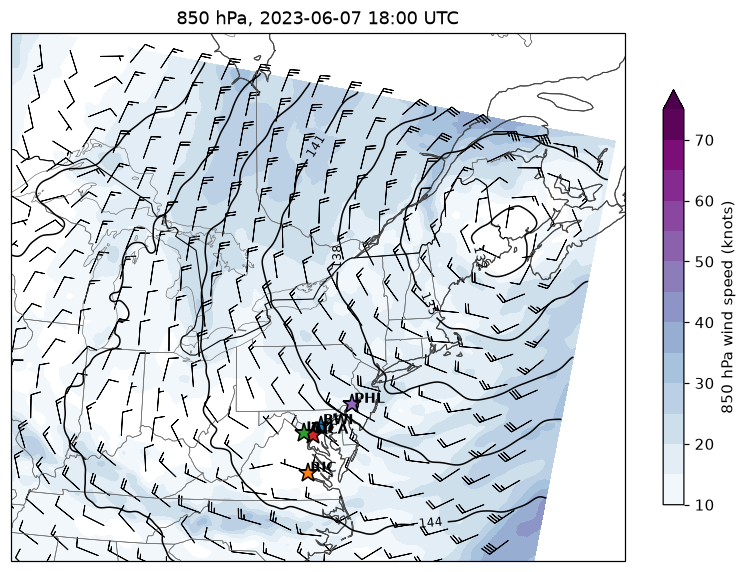

In [24]:
pressure_level_map(map_time, 850, interval=3)

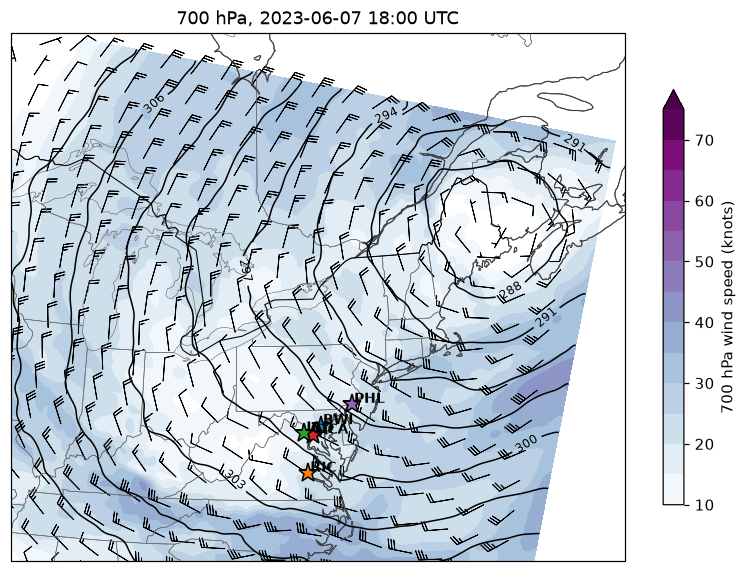

In [25]:
pressure_level_map(map_time, 700, interval=3)

Questions:
- Find the closed low (circle of lines) on the 500 hPa map. In June 2023 a low sat near Maine and Nova Scotia.
- Do the winds west of the low come from Quebec?

## 19. Smoke and wind together
Column smoke with 700 hPa winds. If the barbs follow the smoke, the wind explains where it went.

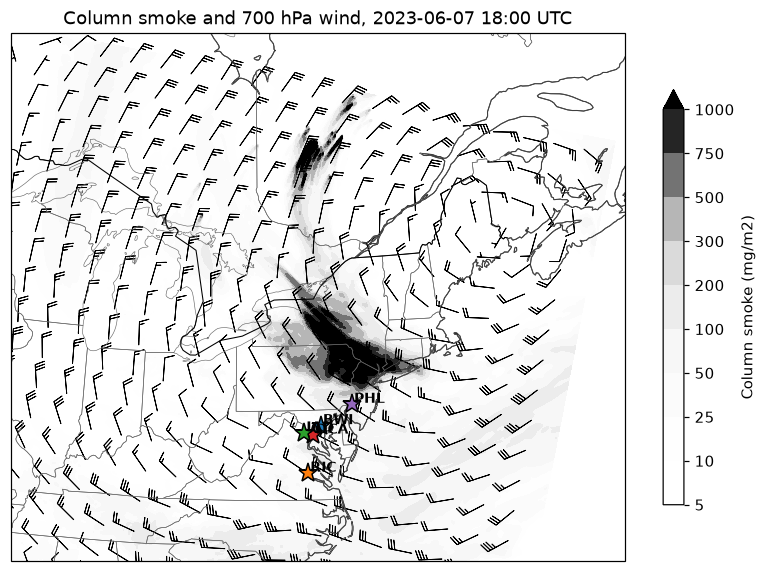

In [26]:
u700 = get_hrrr(map_time, ":UGRD:700 mb", product="prs")
v700 = get_hrrr(map_time, ":VGRD:700 mb", product="prs")

fig, ax = make_map(wide_extent, f"Column smoke and 700 hPa wind, {map_time} UTC")
cf = ax.contourf(smoke_col.longitude, smoke_col.latitude, smoke_col, levels=col_levels,
                 cmap="Greys", extend="max", transform=ccrs.PlateCarree())
plt.colorbar(cf, ax=ax, shrink=0.7, label="Column smoke (mg/m2)")
add_barbs(ax, u700, v700)
add_stations(ax)
plt.show()

## 20. Summary
- ASOS showed low visibility and smoke reports at the airports.
- HRRR-Smoke showed where the smoke was, near the ground and aloft.
- Weather maps showed the winds that carried smoke from Quebec.

Limits:
- ASOS measures weather, not pollution.
- HRRR-Smoke is a model and only includes wildfire smoke.
- For measured PM2.5 use EPA AirNow (airnow.gov).

## 21. Try it yourself
1. Set `map_time = "2023-06-08 12:00"` and run again.
2. Use `fxx=6` in `get_hrrr` to look at a 6-hour forecast.
3. Make a 925 hPa map: `pressure_level_map(map_time, 925, interval=3)`.
4. Add other airports, for example DOV, MDT or ACY.